# Poisson PFDM — numerics-informed hyperparameter experiment

We use
\[
\tau=p=2,\qquad C=\widehat C_{\rm defect},\qquad \sigma_f=\|u_h\|_\infty,
\]
and choose the Matérn-3/2 length scale from the adjacent-grid prior correlation
\(\rho(h)\in\{0.3,0.5,0.7,0.8\}\).

The experiment is repeated for \(h\in\{0.75,0.4,0.2,0.05\}\).


In [1]:
using LinearAlgebra
using Statistics
using Printf
using Plots


In [2]:
# ============================================================
# Poisson PFDM: numerics-informed hyperparameter experiment
#
#   -u''(x) = sin(2πx),  x ∈ (0,18)
#   u(0)=u(18)=0
#
# Hyperparameters:
#   τ = p = 2
#   C = coarsening-defect estimator
#   σf = ||u_h||_∞
#   ℓ chosen from adjacent-grid prior correlation ρ(h)
#
# Matérn-3/2:
#   ρ(r) = (1 + sqrt(3) r/ℓ) exp(-sqrt(3) r/ℓ)


In [3]:
# ============================================================

# -------------------------------
# Problem
# -------------------------------
L_domain = 18.0

u_exact(x) = sin(2π*x) / (2π)^2
f_func(x)  = sin(2π*x)

ν_fixed = 1.5
p_order = 2
τ_fixed = 2

h_list   = [0.75, 0.4, 0.2, 0.05]
rho_grid = [0.3, 0.5, 0.7, 0.8]

jitter = 1e-10

# -------------------------------
# Matérn-3/2 kernel
# -------------------------------
function matern32_kernel(x1, x2; ℓ=1.0, σf=1.0)
    r = abs(x1 - x2)
    z = sqrt(3.0) * r / ℓ
    return σf^2 * (1.0 + z) * exp(-z)
end

function kernel_matrix_matern32(X1, X2; ℓ=1.0, σf=1.0)
    [matern32_kernel(x1, x2; ℓ=ℓ, σf=σf) for x1 in X1, x2 in X2]
end

# -------------------------------
# Convert target adjacent correlation rho(h)
# to length scale ℓ for Matérn-3/2.
#
# Solve (1+z) exp(-z) = rho,
# where z = sqrt(3) h / ℓ.
# -------------------------------
function ell_from_rho(h, rho; tol=1e-12, maxiter=200)
    @assert 0.0 < rho < 1.0

    fz(z) = (1.0 + z) * exp(-z) - rho

    lo = 0.0
    hi = 1.0
    while fz(hi) > 0.0
        hi *= 2.0
    end

    for _ in 1:maxiter
        mid = 0.5 * (lo + hi)
        if fz(mid) > 0.0
            lo = mid
        else
            hi = mid
        end
        if hi - lo < tol
            break
        end
    end

    z = 0.5 * (lo + hi)
    return sqrt(3.0) * h / z
end

# -------------------------------
# Standard FDM
# -------------------------------
function solve_fdm(h)
    # all h in h_list divide 18 exactly
    x_all = collect(0.0:h:L_domain)
    x_int = x_all[2:end-1]
    n_int = length(x_int)

    A = SymTridiagonal(
        fill( 2.0/h^2, n_int),
        fill(-1.0/h^2, n_int-1)
    )

    rhs = f_func.(x_int)
    u_int = A \ rhs

    return x_all, vcat(0.0, u_int, 0.0)
end

# -------------------------------
# Observation matrix H = -Δ_h,
# with boundary identity rows
# -------------------------------
function observation_matrix(n_total, h)
    n_int = n_total - 2
    H = zeros(n_total, n_total)

    H[1,1] = 1.0
    H[end,end] = 1.0

    for i in 1:n_int
        H[i+1, i]   = -1.0/h^2
        H[i+1, i+1] =  2.0/h^2
        H[i+1, i+2] = -1.0/h^2
    end

    return H
end

make_y_train(x_all) =
    vcat(0.0, f_func.(x_all[2:end-1]), 0.0)

# -------------------------------
# C calibration from coarsening defect
#
# If
#   D_h u - f = c(x) h^p + ...
#
# then approximately
#   D_{2h} u_h - f
#       = (2^p - 1) c(x) h^p + ...
#
# so
#   c_hat = defect / ((2^p - 1) h^p)
#   C_hat = mean(c_hat.^2)
# -------------------------------
function estimate_C_coarsening(h; p=2)
    x_h, u_h = solve_fdm(h)
    n = length(x_h)

    # 2h stencil uses i-2, i, i+2.
    # Use every valid center, not only every-other center.
    idx = collect(3:(n-2))

    h2 = 2.0*h
    defect = zeros(length(idx))

    for (k,i) in enumerate(idx)
        D2h_u = (-u_h[i-2] + 2u_h[i] - u_h[i+2]) / h2^2
        defect[k] = D2h_u - f_func(x_h[i])
    end

    c_hat = defect ./ ((2.0^p - 1.0) * h^p)
    C_hat = mean(c_hat.^2)

    return C_hat, x_h[idx], c_hat, defect
end

# -------------------------------
# Oracle C for diagnostics only
# -------------------------------
function oracle_C(h; p=2)
    x_h, _ = solve_fdm(h)
    n = length(x_h)

    # use same centers as coarsening estimator
    idx = collect(3:(n-2))
    c_true = zeros(length(idx))

    for (k,i) in enumerate(idx)
        Dh_u = (
            -u_exact(x_h[i-1])
            + 2u_exact(x_h[i])
            - u_exact(x_h[i+1])
        ) / h^2

        e_h = Dh_u - f_func(x_h[i])
        c_true[k] = e_h / h^p
    end

    return mean(c_true.^2)
end

# -------------------------------
# PFDM posterior
# -------------------------------
function run_pfdm(
    h;
    rho_adj,
    C,
    σf,
    τ=2,
    n_test=1000
)
    x_all = collect(0.0:h:L_domain)
    n_total = length(x_all)

    H = observation_matrix(n_total, h)
    y = make_y_train(x_all)

    ℓ = ell_from_rho(h, rho_adj)

    noise_var = C * h^(2τ)
    Σ_diag = vcat(
        0.0,
        fill(noise_var, n_total-2),
        0.0
    )
    Σobs = Diagonal(Σ_diag)

    K = kernel_matrix_matern32(
        x_all, x_all; ℓ=ℓ, σf=σf
    )

    Kobs = H*K*H' + Σobs + jitter*I
    chol = cholesky(Hermitian(Kobs))

    Xtest = collect(range(0.0, L_domain, length=n_test))

    Ktx = kernel_matrix_matern32(
        Xtest, x_all; ℓ=ℓ, σf=σf
    )

    Ks = Ktx * H'
    Kss = kernel_matrix_matern32(
        Xtest, Xtest; ℓ=ℓ, σf=σf
    )

    μ = Ks * (chol \ y)
    Σpost = Kss - Ks * (chol \ Ks')

    s = sqrt.(max.(diag(Σpost), 0.0))
    utrue = u_exact.(Xtest)

    return Xtest, μ, s, utrue, ℓ
end

# -------------------------------
# Metrics
# -------------------------------
function metrics(μ, s, utrue)
    err = μ .- utrue

    rmse = sqrt(mean(err.^2))
    linf = maximum(abs.(err))

    lower = μ .- 1.96 .* s
    upper = μ .+ 1.96 .* s

    coverage = mean((utrue .>= lower) .& (utrue .<= upper))
    mean_halfwidth = mean(1.96 .* s)

    return rmse, linf, coverage, mean_halfwidth
end


metrics (generic function with 1 method)

In [4]:
# ============================================================
# Run experiment


In [5]:
# ============================================================
results = NamedTuple[]

println("=== Poisson: numerics-informed hyperparameters ===")
println("tau = p = 2")
println("sigma_f = ||u_h||_inf")
println("C = coarsening defect")
println("ell determined by rho(h)")
println()

for h in h_list
    x_h, u_h = solve_fdm(h)

    σf_rms = sqrt(mean(u_h.^2))
    σf_max = maximum(abs.(u_h))
    σf_used = σf_max

    C_hat, _, c_hat, _ =
        estimate_C_coarsening(h; p=p_order)

    C_or = oracle_C(h; p=p_order)

    println("-------------------------------------------")
    @printf("h = %.6g\n", h)
    @printf("sigma_rms = %.6g\n", σf_rms)
    @printf("sigma_max = %.6g\n", σf_max)
    @printf("C_hat     = %.6g\n", C_hat)
    @printf("C_oracle  = %.6g\n", C_or)
    @printf("C ratio   = %.6g\n", C_hat/C_or)
    @printf("RMS(c_hat)= %.6g\n", sqrt(mean(c_hat.^2)))

    for rho in rho_grid
        X, μ, s, utrue, ℓ = run_pfdm(
            h;
            rho_adj=rho,
            C=C_hat,
            σf=σf_used,
            τ=τ_fixed
        )

        rmse, linf, coverage, mean_hw =
            metrics(μ, s, utrue)

        push!(results, (
            h=h,
            rho=rho,
            ell=ℓ,
            ell_over_h=ℓ/h,
            sigma_rms=σf_rms,
            sigma_max=σf_max,
            sigma_used=σf_used,
            C_hat=C_hat,
            C_oracle=C_or,
            C_ratio=C_hat/C_or,
            rmse=rmse,
            linf=linf,
            coverage=coverage,
            mean_CI_halfwidth=mean_hw
        ))

        @printf(
            "rho=%.1f  ell/h=%.3f  RMSE=%.5g  Linf=%.5g  coverage=%.3f  CIhalf=%.5g\n",
            rho, ℓ/h, rmse, linf, coverage, mean_hw
        )
    end
end


=== Poisson: numerics-informed hyperparameters ===
tau = p = 2
sigma_f = ||u_h||_inf
C = coarsening defect
ell determined by rho(h)

-------------------------------------------
h = 0.75
sigma_rms = 0.194856
sigma_max = 0.28125
C_hat     = 0.0418055
C_oracle  = 1.24611
C ratio   = 0.0335487
RMS(c_hat)= 0.204464
rho=0.3  ell/h=0.710  RMSE=0.17552  Linf=0.253  coverage=0.970  CIhalf=0.33338
rho=0.5  ell/h=1.032  RMSE=0.18458  Linf=0.25476  coverage=0.952  CIhalf=0.31788
rho=0.7  ell/h=1.578  RMSE=0.18677  Linf=0.26041  coverage=0.912  CIhalf=0.32917
rho=0.8  ell/h=2.101  RMSE=0.18445  Linf=0.2684  coverage=0.890  CIhalf=0.34632
-------------------------------------------
h = 0.4
sigma_rms = 0.0309286
sigma_max = 0.0420585
C_hat     = 1.84387
C_oracle  = 3.702
C ratio   = 0.498073
RMS(c_hat)= 1.35789
rho=0.3  ell/h=0.710  RMSE=0.0078855  Linf=0.014792  coverage=1.000  CIhalf=0.063124
rho=0.5  ell/h=1.032  RMSE=0.0063678  Linf=0.013103  coverage=1.000  CIhalf=0.064458
rho=0.7  ell/h=1.578  

In [6]:
# ============================================================
# Print compact table


In [7]:
# ============================================================
println("\n=== Compact results table ===")
@printf(
    "%-7s %-6s %-8s %-11s %-11s %-10s %-10s %-10s\n",
    "h","rho","ell/h","C_hat","C_oracle","RMSE","Linf","coverage"
)

for r in results
    @printf(
        "%-7.3g %-6.2f %-8.3f %-11.4g %-11.4g %-10.4g %-10.4g %-10.3f\n",
        r.h, r.rho, r.ell_over_h,
        r.C_hat, r.C_oracle,
        r.rmse, r.linf, r.coverage
    )
end



=== Compact results table ===
h       rho    ell/h    C_hat       C_oracle    RMSE       Linf       coverage  
0.75    0.30   0.710    0.04181     1.246       0.1755     0.253      0.970     
0.75    0.50   1.032    0.04181     1.246       0.1846     0.2548     0.952     
0.75    0.70   1.578    0.04181     1.246       0.1868     0.2604     0.912     
0.75    0.80   2.101    0.04181     1.246       0.1844     0.2684     0.890     
0.4     0.30   0.710    1.844       3.702       0.007886   0.01479    1.000     
0.4     0.50   1.032    1.844       3.702       0.006368   0.0131     1.000     
0.4     0.70   1.578    1.844       3.702       0.004447   0.01053    1.000     
0.4     0.80   2.101    1.844       3.702       0.005957   0.01436    1.000     
0.2     0.30   0.710    4.115       4.837       0.001483   0.003286   1.000     
0.2     0.50   1.032    4.115       4.837       0.001849   0.003402   1.000     
0.2     0.70   1.578    4.115       4.837       0.002083   0.003787   1.000   

In [8]:
# ============================================================
# 4-panel plot for one chosen rho


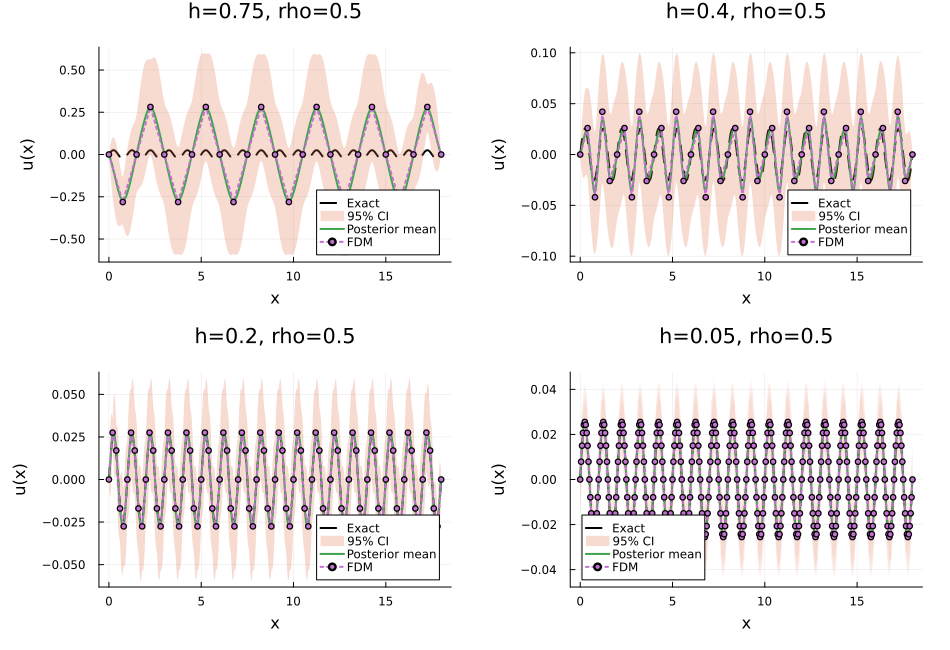


Saved: poisson_proposed_hyperparams_rho05.png


In [9]:
# ============================================================
rho_plot = 0.5
panels = []

for h in h_list
    x_h, u_h = solve_fdm(h)
    σf_used = maximum(abs.(u_h))
    C_hat, _, _, _ =
        estimate_C_coarsening(h; p=p_order)

    X, μ, s, utrue, ℓ = run_pfdm(
        h;
        rho_adj=rho_plot,
        C=C_hat,
        σf=σf_used,
        τ=τ_fixed
    )

    p = plot(
        X, utrue;
        label="Exact",
        color=:black,
        ls=:dash,
        lw=2,
        xlabel="x",
        ylabel="u(x)",
        title="h=$(h), rho=$(rho_plot)"
    )

    plot!(
        p,
        X, μ .+ 1.96 .* s;
        fillrange=μ .- 1.96 .* s,
        fillalpha=0.25,
        linealpha=0,
        label="95% CI"
    )

    plot!(
        p,
        X, μ;
        label="Posterior mean",
        lw=2
    )

    plot!(
        p,
        x_h, u_h;
        label="FDM",
        ls=:dot,
        lw=2,
        marker=:circle,
        markersize=3
    )

    push!(panels, p)
end

fig = plot(
    panels...;
    layout=(2,2),
    size=(950,650),
    margin=5Plots.mm
)

display(fig)
savefig(fig, "poisson_proposed_hyperparams_rho05.png")
println("\nSaved: poisson_proposed_hyperparams_rho05.png")
